## Прогноз числа актов в месяц

In [10]:
# импорты
import sqlite3
import time

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error

from src.config import DB_PATH, DOCS

### 1. Данные
Число актов в месяц за 2000–2025 из базы (до 2000 года ряд маленький и нестабильный — по итогам аудита).

In [11]:
# актов по месяцам из SQL
conn = sqlite3.connect(DB_PATH)
m = pd.read_sql("""
    SELECT substr(date_adopted, 1, 7) AS month, COUNT(*) AS acts
    FROM acts
    WHERE year BETWEEN 2000 AND 2025
    GROUP BY month
    ORDER BY month
""", conn)
conn.close()

# месячный ряд с датой-индексом
m["month"] = pd.to_datetime(m["month"])
series = m.set_index("month")["acts"].asfreq("MS")
series.tail()

month
2025-08-01     834
2025-09-01    1316
2025-10-01    1194
2025-11-01    1437
2025-12-01    2392
Freq: MS, Name: acts, dtype: int64

### 2. Разбиение train / test
По времени, без перемешивания: обучаем на 2000–2023, проверяем на 2024–2025. Модели не видят будущее — утечки данных нет.

In [12]:
# делим по времени
train = series[:"2023-12"]
test = series["2024-01":]
h = len(test) # горизонт прогноза = 24 месяца
print("train:", len(train), "мес.,", "test:", h, "мес.")

train: 288 мес., test: 24 мес.


### 3. Модели
- **Baseline:** naive (как прошлый месяц) и seasonal naive (как тот же месяц год назад).
- **Подход 1:** скользящее среднее за 12 месяцев.
- **Подход 2:** линейная регрессия — тренд + месяц года; два варианта обучения: 2000–2023 и 2016–2023.

In [13]:
# прогнозы и время моделей
forecasts = {}
times = {}

# naive: последнее значение train
start = time.perf_counter()
forecasts["naive"] = np.repeat(train.iloc[-1], h)
times["naive"] = time.perf_counter() - start

# seasonal naive: год назад
start = time.perf_counter()
forecasts["seasonal_naive"] = np.tile(train.iloc[-12:].values, 2)[:h]
times["seasonal_naive"] = time.perf_counter() - start

In [14]:
# среднее последних 12 месяцев
start = time.perf_counter()
forecasts["moving_avg_12"] = np.repeat(train.iloc[-12:].mean(), h)
times["moving_avg_12"] = time.perf_counter() - start

In [15]:
# признаки: тренд + месяц
def make_features(index, origin):
    """Признаки для регрессии: номер месяца от начала (тренд) + месяц года (сезон)."""
    t = (index.year - origin.year) * 12 + (index.month - origin.month)

    X = pd.get_dummies(index.month, prefix="m", drop_first=True).astype(int)
    X.insert(0, "t", t)
    return X

# регрессия на двух периодах
for name, since in [("linreg_2000", "2000-01"), ("linreg_2016", "2016-01")]:
    part = train[since:]
    start = time.perf_counter()
    # обучаем и прогнозируем
    model = LinearRegression().fit(make_features(part.index, part.index[0]), part.values)
    forecasts[name] = model.predict(make_features(test.index, part.index[0]))
    times[name] = time.perf_counter() - start

### 4. Сравнение
MAE — на сколько актов в месяц модель в среднем ошибается (меньше — лучше). Время — сколько миллисекунд заняло обучение и прогноз.

In [16]:
# MAE и время моделей
results = pd.DataFrame([
    {
        "model": name,
        "MAE": round(mean_absolute_error(test.values, pred), 1),
        "time_ms": round(times[name] * 1000, 2),
    }
    for name, pred in forecasts.items()
]).sort_values("MAE")

# сохраняем таблицу метрик
results.to_csv(DOCS / "forecast_mae.csv", index=False, encoding="utf-8-sig")
results

,model,MAE,time_ms
4,linreg_2016,214.8,17.61
3,linreg_2000,257.5,16.05
1,seasonal_naive,300.8,0.71
2,moving_avg_12,351.8,0.82
0,naive,1828.6,0.41


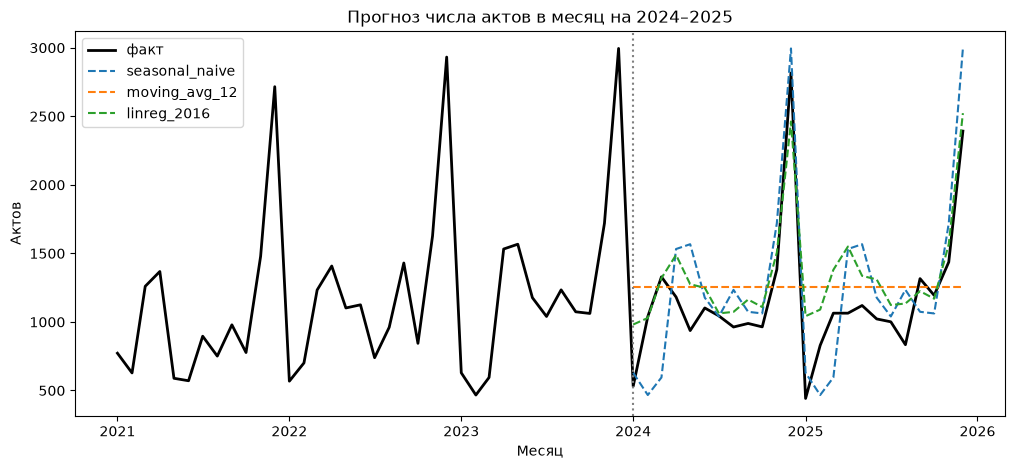

In [17]:
# факт против прогнозов
fig, ax = plt.subplots(figsize=(12, 5))
ax.plot(series["2021":].index, series["2021":].values, color="black", linewidth=2, label="факт")
for name in ["seasonal_naive", "moving_avg_12", "linreg_2016"]:
    ax.plot(test.index, forecasts[name], linestyle="--", label=name)
ax.axvline(test.index[0], color="gray", linestyle=":")   # граница train | test
ax.set_title("Прогноз числа актов в месяц на 2024–2025")
ax.set_xlabel("Месяц")
ax.set_ylabel("Актов")
ax.legend()
plt.show()

## Итоги прогноза

| Модель | Тип | MAE |
|---|---|---|
| linreg_2016 | подход 2 | **214.8** |
| linreg_2000 | подход 2 | 257.5 |
| seasonal_naive | baseline | 300.8 |
| moving_avg_12 | подход 1 | 351.8 |
| naive | baseline | 1828.6 |

- **naive** — худший: последний месяц train — декабрь со всплеском, и этот всплеск растянут на все 2 года.
- **seasonal naive** — сильный baseline: он повторяет прошлый год и поэтому учитывает декабрьский пик.
- **Скользящее среднее** хуже seasonal naive: одно число на все месяцы, сезонность не видна.
- **Линейная регрессия** с трендом и месяцами года лучше обоих baseline. Обученная на 2016–2023 — лучшая (MAE 214.8, на **29 % лучше** seasonal naive): после 2015 года актов стало в разы больше, и старые данные только мешают.
- **Время:** все модели работают за миллисекунды, по скорости разницы нет — выбор делаем по MAE.
- **Вывод:** для прогноза числа актов выбираем линейную регрессию (тренд + сезонность) на данных с 2016 года.